# Move-size test

Can we predict how big tomorrow's move will be, ignoring its direction, and does news help? The target is the next day's absolute log return. Big moves tend to follow big moves, so unlike the return target, this one has a known pattern for news to add to.

All 4 input sets get each day's absolute return as an extra input, so news can't look useful just by supplying volatility. Walk-forward is the main evidence, and 80/10/10 is a second view. The test split stays locked. All runs use 3 seeds, common dates and standardization.

**Baselines:** the train mean, yesterday's move, the 5-day and 20-day average moves, and **HAR** (Corsi, 2009), a linear regression on the 1, 5 and 22-day average moves. HAR is the main baseline.

**The questions, fixed before any results, in order:**

1. **Is there a pattern?** HAR's R² interval must be above zero against the train mean, or the test stops there.
2. **Does a trained model add anything?** Its MSE improvement over HAR must have an interval above zero, with MAE and rank correlation not clearly worse.
3. **Does news help?** With the same model, news must beat no news on the same terms.

If news wins, a shuffled-news placebo and the news audit come before trusting it.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.data import NEWS_WITH_FEATURES, NO_NEWS_NO_FEATURES
from benchmarking.move_size import (
    big_move_scores,
    compare_news,
    compare_to_har,
    move_intervals,
    rolling_baselines,
    run_move_split,
    run_move_walk_forward,
)
from benchmarking.result_plots import plot_move_comparisons, plot_move_intervals, plot_move_predictions
from benchmarking.walk_forward import score_walk_forward

RESULTS_DIR = Path.cwd().parent / "results"

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

## Training

HAR is fitted once per round and has no randomness. Saved work is skipped.

In [2]:
run_move_walk_forward(RESULTS_DIR / "move_size_walk_forward_predictions.csv")
run_move_split(RESULTS_DIR / "move_size_split_predictions.csv")

## Load saved results

The simple baselines need no training, and only use moves from before each scored day.

In [3]:
trained = pd.read_csv(RESULTS_DIR / "move_size_walk_forward_predictions.csv")
walk_forward = pd.concat([trained, rolling_baselines(trained)], ignore_index=True)
split = pd.read_csv(RESULTS_DIR / "move_size_split_predictions.csv")
validation = split[split["split"] == "validation"]


def scale(table):
    """Show tiny MSE and MAE values multiplied by 10,000."""
    columns = [c for c in table.columns if c.startswith(("mse", "mae", "baseline_m")) and "skill" not in c]
    return table.assign(**{column: table[column] * 1e4 for column in columns})

## Walk-forward

### Walk-forward: results with confidence intervals

781 scored days. `oos_r2` and `mae_skill` are relative to the train mean. `spread_ratio` is prediction spread divided by actual spread. MSE and MAE are shown multiplied by 10,000.

In [4]:
intervals = move_intervals(walk_forward)
intervals.to_csv(RESULTS_DIR / "move_size_walk_forward_intervals.csv", index=False)
scale(intervals).drop(columns=["horizon", "days"]).sort_values("oos_r2", ascending=False)

,track,model,mse,baseline_mse,mae,baseline_mae,spread_ratio,oos_r2,oos_r2_lower,oos_r2_upper,mae_skill,mae_skill_lower,mae_skill_upper,correlation,correlation_lower,correlation_upper,rank_correlation,rank_correlation_lower,rank_correlation_upper
12,no_news_with_feature_engineering,XGBoost | Stronger,5.2777,5.3849,162.7566,165.6944,0.1417,0.0199,-0.0018,0.0446,0.0177,0.0018,0.0351,0.1337,0.0530,0.2097,0.0925,0.0133,0.1672
8,no_news_with_feature_engineering,LSTM,5.2939,5.3849,161.2669,165.6944,0.2188,0.0169,-0.0194,0.0568,0.0267,0.0024,0.0539,0.1613,0.0790,0.2280,0.1177,0.0367,0.1847
25,news_with_feature_engineering_and_tech,XGBoost | Stronger,5.3108,5.3849,163.1343,165.6944,0.1333,0.0138,-0.0120,0.0392,0.0155,-0.0024,0.0332,0.1057,0.0158,0.1958,0.0796,-0.0023,0.1528
11,no_news_with_feature_engineering,LSTM | Dropout 0.5,5.3130,5.3849,160.6242,165.6944,0.1903,0.0133,-0.0218,0.0487,0.0306,0.0085,0.0524,0.1344,0.0303,0.2124,0.0913,-0.0074,0.1766
6,no_news_no_feature_engineering,HAR,5.3197,5.3849,162.5361,165.6944,0.2319,0.0121,-0.0196,0.0508,0.0191,-0.0120,0.0533,0.1323,0.0539,0.1999,0.1326,0.0477,0.1891
9,no_news_with_feature_engineering,XGBoost,5.3227,5.3849,164.5274,165.6944,0.1682,0.0116,-0.0135,0.0378,0.0070,-0.0108,0.0263,0.1261,0.0536,0.2006,0.1005,0.0202,0.1737
2,no_news_no_feature_engineering,XGBoost,5.3395,5.3849,163.4319,165.6944,0.1740,0.0084,-0.0223,0.0405,0.0137,-0.0080,0.0346,0.1184,0.0344,0.2062,0.1015,0.0257,0.1706
15,news_with_feature_engineering,XGBoost,5.3412,5.3849,163.7193,165.6944,0.1513,0.0081,-0.0206,0.0355,0.0119,-0.0073,0.0285,0.1101,0.0122,0.2008,0.1093,0.0244,0.1876
18,news_with_feature_engineering,XGBoost | Stronger,5.3480,5.3849,162.8054,165.6944,0.1321,0.0069,-0.0185,0.0295,0.0174,0.0029,0.0327,0.0792,-0.0158,0.1563,0.0600,-0.0250,0.1390
5,no_news_no_feature_engineering,XGBoost | Stronger,5.3536,5.3849,163.8109,165.6944,0.1329,0.0058,-0.0157,0.0282,0.0114,-0.0038,0.0284,0.0756,0.0022,0.1495,0.0664,-0.0066,0.1347


### Walk-forward: chart

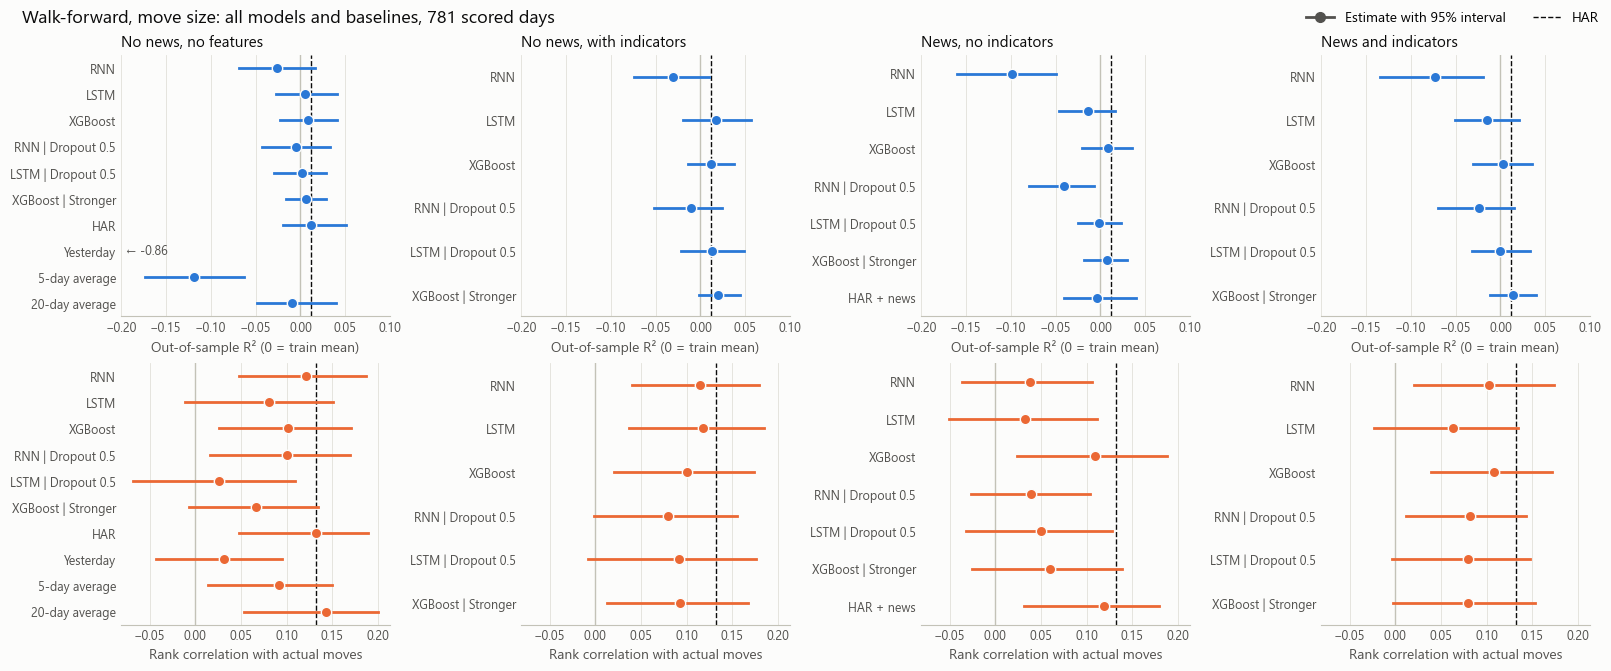

In [5]:
plot_move_intervals(
    intervals,
    title="Walk-forward, move size: all models and baselines, 781 scored days",
    r2_limits=(-0.2, 0.1),
)

### Walk-forward: catching big moves

A big move is above the 80th percentile of moves known before that round. `caught` is the share of big moves the model flagged, and `precision` is the share of flagged days that were big. Compare `precision` with `big_share`, which is what flagging at random would get.

In [6]:
big_move_scores(walk_forward).sort_values("caught", ascending=False)

,track,model,big_share,flagged_share,caught,precision
26,no_news_no_feature_engineering,Yesterday,0.1831,0.1844,0.1958,0.1944
27,no_news_no_feature_engineering,5-day average,0.1831,0.0909,0.1469,0.2958
28,no_news_no_feature_engineering,20-day average,0.1831,0.0423,0.0909,0.3939
0,no_news_no_feature_engineering,RNN,0.1831,0.0269,0.0629,0.4286
7,no_news_with_feature_engineering,RNN,0.1831,0.0179,0.0350,0.3571
13,news_with_feature_engineering,RNN,0.1831,0.0115,0.0350,0.5556
1,no_news_no_feature_engineering,LSTM,0.1831,0.0179,0.0280,0.2857
20,news_with_feature_engineering_and_tech,RNN,0.1831,0.0192,0.0280,0.2667
19,news_with_feature_engineering,HAR + news,0.1831,0.0166,0.0280,0.3077
8,no_news_with_feature_engineering,LSTM,0.1831,0.0179,0.0280,0.2857


### Walk-forward: results by round

Out-of-sample R² per round, averaged across seeds.

In [7]:
rounds = score_walk_forward(walk_forward, by_round=True)
rounds.pivot_table(index=["track", "model"], columns="round", values="oos_r2", sort=False)

round                                                           1       2       3       4       5       6       7       8
track                                  model                                                                             
no_news_no_feature_engineering         RNN                -0.1594 -0.1083 -0.0179  0.0124  0.0096 -0.0024 -0.0066  0.0940
                                       LSTM               -0.1018 -0.0590  0.0211  0.1529  0.0146  0.0111  0.0081  0.0724
                                       XGBoost            -0.1255 -0.0023  0.0288  0.0621  0.0155 -0.0134  0.0442  0.0838
                                       RNN | Dropout 0.5  -0.1050 -0.1030  0.0117  0.1168  0.0203 -0.0313  0.0350  0.0891
                                       LSTM | Dropout 0.5 -0.1336 -0.0406 -0.0156  0.1049  0.0363  0.0047  0.0484  0.0693
                                       XGBoost | Stronger -0.1120 -0.0013  0.0107  0.0840  0.0156  0.0001  0.0137  0.0781
                                       HAR                -0.0433 -0.0778  0.0589  0.1716 -0.0266  0.0223  0.0202  0.0475
                                       Yesterday          -1.0228 -1.2301 -0.8873 -0.6306 -0.8893 -0.9043 -0.5672 -0.6342
                                       5-day average      -0.1704 -0.2667 -0.0545  0.0803 -0.1717 -0.1202 -0.1124 -0.0350
                                       20-day average     -0.0419 -0.0318  0.0339  0.1713 -0.0806  0.0130 -0.0351 -0.0247
no_news_with_feature_engineering       RNN                -0.1361 -0.1151 -0.0232  0.0039 -0.0289 -0.0011 -0.0054  0.0850
                                       LSTM               -0.1089 -0.0581  0.0420  0.1394  0.0681  0.0208  0.0102  0.0929
                                       XGBoost            -0.0652 -0.0063  0.0094  0.0547  0.0343 -0.0016  0.0077  0.0899
                                       RNN | Dropout 0.5  -0.1153 -0.0789  0.0238  0.0215  0.0082 -0.0203  0.0233  0.0672
                                       LSTM | Dropout 0.5 -0.0916 -0.0702  0.0351  0.1050  0.0581 -0.0027  0.0290  0.1003
                                       XGBoost | Stronger -0.0728 -0.0028  0.0060  0.0949  0.0394  0.0149  0.0339  0.0912
news_with_feature_engineering          RNN                -0.3762 -0.1356 -0.0257 -0.1189 -0.0683 -0.0564 -0.0461  0.0098
                                       LSTM               -0.1385 -0.0351 -0.0149  0.1419  0.0390 -0.0685  0.0168  0.0349
                                       XGBoost            -0.1136 -0.0031  0.0097  0.0307  0.0294  0.0037  0.0291  0.0937
                                       RNN | Dropout 0.5  -0.1800 -0.1196  0.0064  0.0093 -0.0107 -0.0104 -0.0332  0.0378
                                       LSTM | Dropout 0.5 -0.0806 -0.0260 -0.0259  0.1398  0.0376 -0.0293  0.0163  0.0435
                                       XGBoost | Stronger -0.1248 -0.0018  0.0133  0.0825  0.0338 -0.0034  0.0129  0.0857
                                       HAR + news         -0.0994 -0.0750  0.0597  0.1806 -0.0310 -0.0213  0.0034  0.0422
news_with_feature_engineering_and_tech RNN                -0.3040 -0.1246 -0.0467 -0.1549  0.0490 -0.0280 -0.0742  0.0708
                                       LSTM               -0.0830 -0.1080  0.0343  0.0546  0.0451 -0.0866 -0.0058  0.0764
                                       XGBoost            -0.1337  0.0053  0.0158  0.0406  0.0204 -0.0195  0.0156  0.1018
                                       RNN | Dropout 0.5  -0.2134 -0.0450  0.0013  0.0308 -0.0110  0.0118 -0.0283  0.0893
                                       LSTM | Dropout 0.5 -0.0825 -0.0896  0.0444  0.0934  0.0524 -0.0416 -0.0055  0.0852
                                       XGBoost | Stronger -0.1060 -0.0033  0.0063  0.1014  0.0367  0.0010  0.0258  0.1004

## Question 2: does a trained model beat HAR?

### Against HAR: table

The same days, compared day by day. Positive differences favor the model. MSE and MAE are shown multiplied by 10,000.

In [8]:
against_har = compare_to_har(walk_forward)
against_har.to_csv(RESULTS_DIR / "move_size_against_har.csv", index=False)
scale(against_har).drop(columns="days")

,track,model,mse_first,mse_second,mae_first,mae_second,rank_first,rank_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,mae_improvement,mae_improvement_lower,mae_improvement_upper,rank_gain,rank_gain_lower,rank_gain_upper
0,no_news_no_feature_engineering,RNN,5.5232,5.3197,166.2622,162.5361,0.1218,0.1326,-0.2035,-0.3700,-0.0149,-3.7260,-7.4880,-0.1363,-0.0108,-0.0725,0.0656
1,no_news_no_feature_engineering,LSTM,5.3582,5.3197,161.9853,162.5361,0.0813,0.1326,-0.0386,-0.1575,0.0893,0.5508,-2.4378,3.4574,-0.0513,-0.1166,0.0234
2,no_news_no_feature_engineering,XGBoost,5.3395,5.3197,163.4319,162.5361,0.1015,0.1326,-0.0198,-0.1747,0.1402,-0.8958,-4.3709,2.4689,-0.0311,-0.1061,0.0541
3,no_news_no_feature_engineering,RNN | Dropout 0.5,5.4098,5.3197,163.9765,162.5361,0.1003,0.1326,-0.0901,-0.2709,0.0952,-1.4404,-5.7695,2.2152,-0.0323,-0.1054,0.0514
4,no_news_no_feature_engineering,LSTM | Dropout 0.5,5.3742,5.3197,163.8462,162.5361,0.0264,0.1326,-0.0545,-0.2285,0.1092,-1.3100,-6.7964,3.2292,-0.1062,-0.1986,-0.0040
5,no_news_no_feature_engineering,XGBoost | Stronger,5.3536,5.3197,163.8109,162.5361,0.0664,0.1326,-0.0339,-0.1889,0.1195,-1.2747,-5.5426,2.8126,-0.0662,-0.1362,0.0217
6,no_news_with_feature_engineering,RNN,5.5475,5.3197,167.9897,162.5361,0.1147,0.1326,-0.2279,-0.3968,-0.0343,-5.4536,-10.0418,-1.5714,-0.0179,-0.0770,0.0560
7,no_news_with_feature_engineering,LSTM,5.2939,5.3197,161.2669,162.5361,0.1177,0.1326,0.0258,-0.1216,0.1969,1.2692,-1.9749,4.3023,-0.0149,-0.0746,0.0551
8,no_news_with_feature_engineering,XGBoost,5.3227,5.3197,164.5274,162.5361,0.1005,0.1326,-0.0030,-0.1704,0.1673,-1.9912,-6.0043,2.0983,-0.0321,-0.1138,0.0599
9,no_news_with_feature_engineering,RNN | Dropout 0.5,5.4438,5.3197,165.3623,162.5361,0.0798,0.1326,-0.1241,-0.2973,0.0670,-2.8261,-7.1487,1.2254,-0.0528,-0.1229,0.0357


### Against HAR: chart

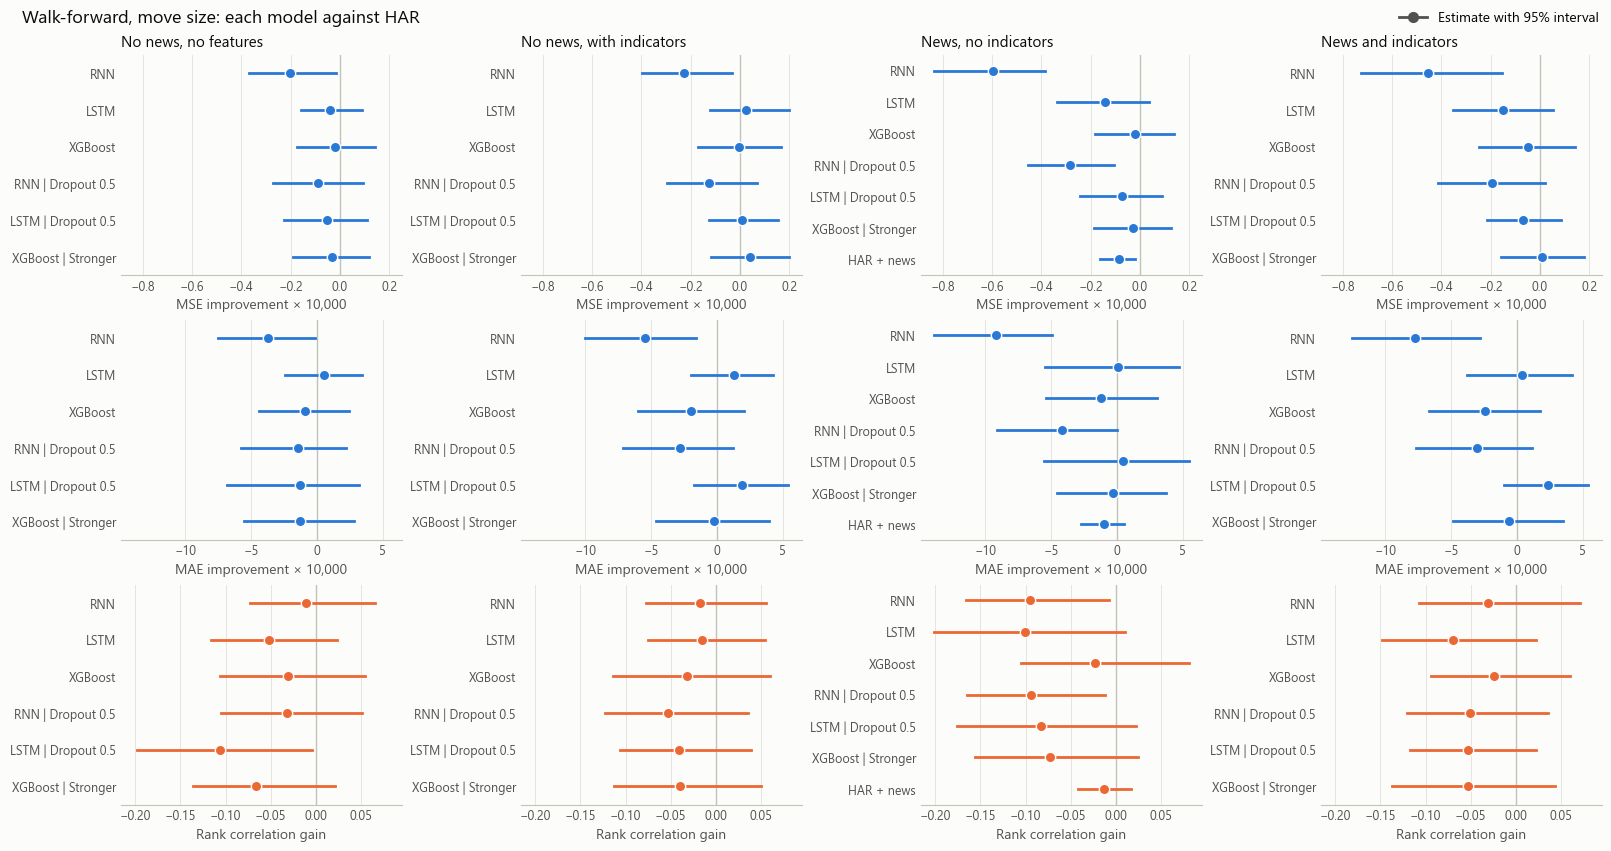

In [9]:
plot_move_comparisons(
    against_har[against_har["model"].isin(trained["model"].unique())],
    "track",
    "Walk-forward, move size: each model against HAR",
)

## Question 3: does news help?

### News against no news: table

The same model on two input sets, compared day by day. Positive differences favor news. MSE and MAE are shown multiplied by 10,000.

In [10]:
news = compare_news(walk_forward)
news.to_csv(RESULTS_DIR / "move_size_news_comparisons.csv", index=False)
scale(news).drop(columns="days")

,comparison,model,mse_first,mse_second,mae_first,mae_second,rank_first,rank_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,mae_improvement,mae_improvement_lower,mae_improvement_upper,rank_gain,rank_gain_lower,rank_gain_upper
0,"News vs no news, no features",RNN,5.9173,5.5232,171.7357,166.2622,0.0379,0.1218,-0.3942,-0.5756,-0.2283,-5.4736,-8.3701,-2.6322,-0.0839,-0.1372,-0.0276
1,"News vs no news, no features",LSTM,5.4618,5.3582,162.4576,161.9853,0.0322,0.0813,-0.1036,-0.2423,0.0369,-0.4723,-4.0916,2.8170,-0.0491,-0.1233,0.0371
2,"News vs no news, no features",XGBoost,5.3412,5.3395,163.7193,163.4319,0.1093,0.1015,-0.0017,-0.0790,0.0707,-0.2873,-2.0999,1.4498,0.0078,-0.0377,0.0587
3,"News vs no news, no features",RNN | Dropout 0.5,5.6032,5.4098,166.6915,163.9765,0.0392,0.1003,-0.1934,-0.3280,-0.0688,-2.7150,-5.4456,-0.1857,-0.0610,-0.1239,0.0026
4,"News vs no news, no features",LSTM | Dropout 0.5,5.3909,5.3742,162.0625,163.8462,0.0498,0.0264,-0.0167,-0.1075,0.0725,1.7837,0.1989,3.4455,0.0234,-0.0278,0.0817
5,"News vs no news, no features",XGBoost | Stronger,5.3480,5.3536,162.8054,163.8109,0.0600,0.0664,0.0056,-0.0316,0.0456,1.0054,0.2160,1.8364,-0.0064,-0.0434,0.0315
6,News + indicators vs indicators,RNN,5.7751,5.5475,170.2693,167.9897,0.1023,0.1147,-0.2276,-0.4095,-0.0327,-2.2796,-5.8094,1.3141,-0.0124,-0.0650,0.0440
7,News + indicators vs indicators,LSTM,5.4677,5.2939,162.1552,161.2669,0.0631,0.1177,-0.1738,-0.3372,-0.0411,-0.8883,-3.5731,1.6087,-0.0546,-0.1267,0.0198
8,News + indicators vs indicators,XGBoost,5.3688,5.3227,164.9924,164.5274,0.1081,0.1005,-0.0462,-0.1183,0.0271,-0.4651,-2.3398,1.2529,0.0076,-0.0267,0.0511
9,News + indicators vs indicators,RNN | Dropout 0.5,5.5131,5.4438,165.5930,165.3623,0.0822,0.0798,-0.0694,-0.2086,0.0615,-0.2307,-3.2667,2.6789,0.0024,-0.0535,0.0593


### News against no news: chart

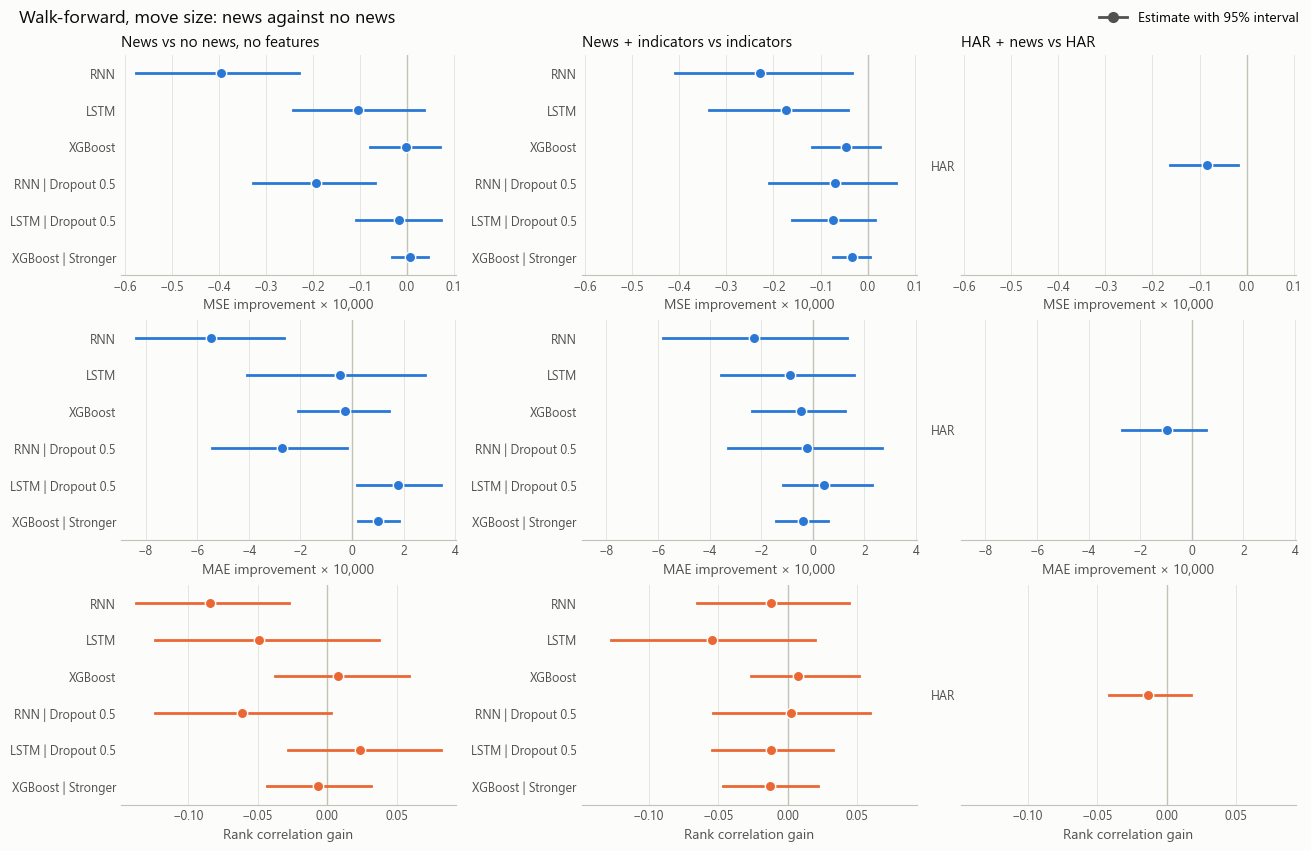

In [11]:
plot_move_comparisons(news, "comparison", "Walk-forward, move size: news against no news")

## Predictions against actual moves

HAR and HAR + news, averaged across seeds, against what actually happened.

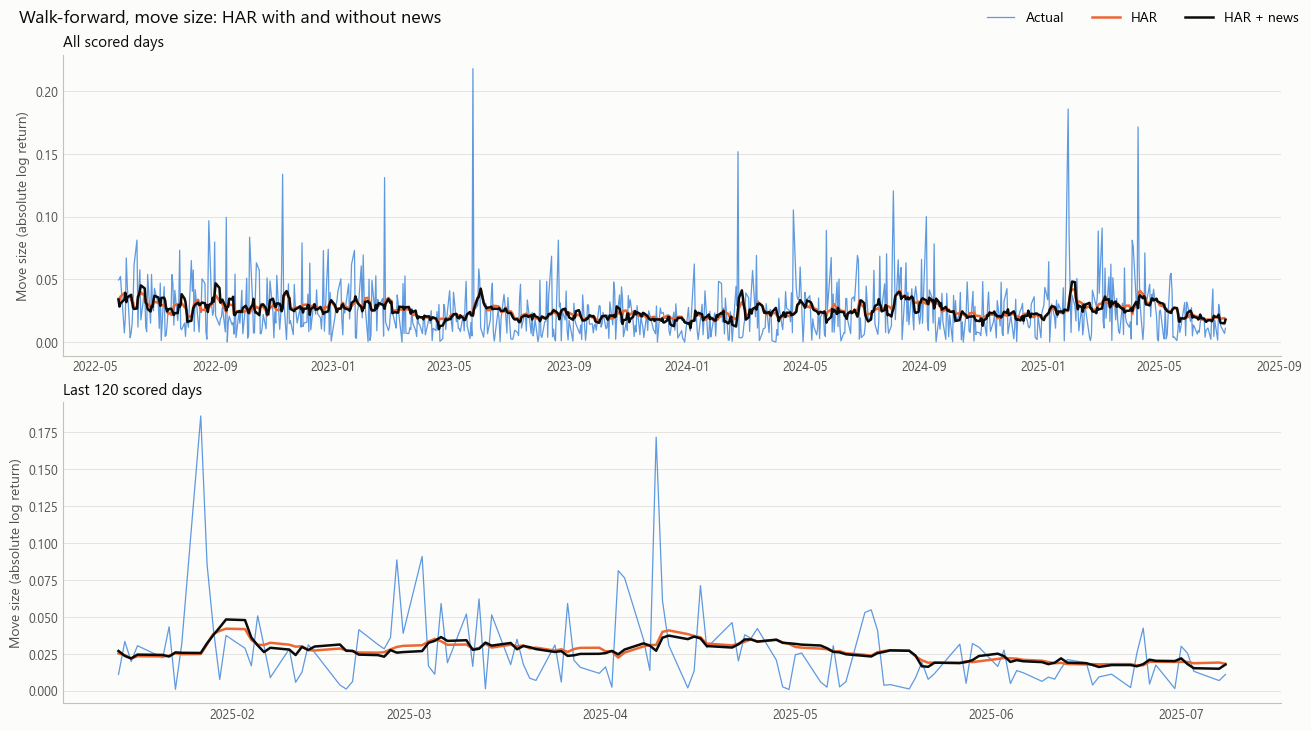

In [12]:
plot_move_predictions(
    walk_forward,
    {"HAR": (NO_NEWS_NO_FEATURES, "HAR"), "HAR + news": (NEWS_WITH_FEATURES, "HAR + news")},
    title="Walk-forward, move size: HAR with and without news",
)

## 80/10/10 split

### 80/10/10: chart

The 123 validation days, which aren't used for early stopping.

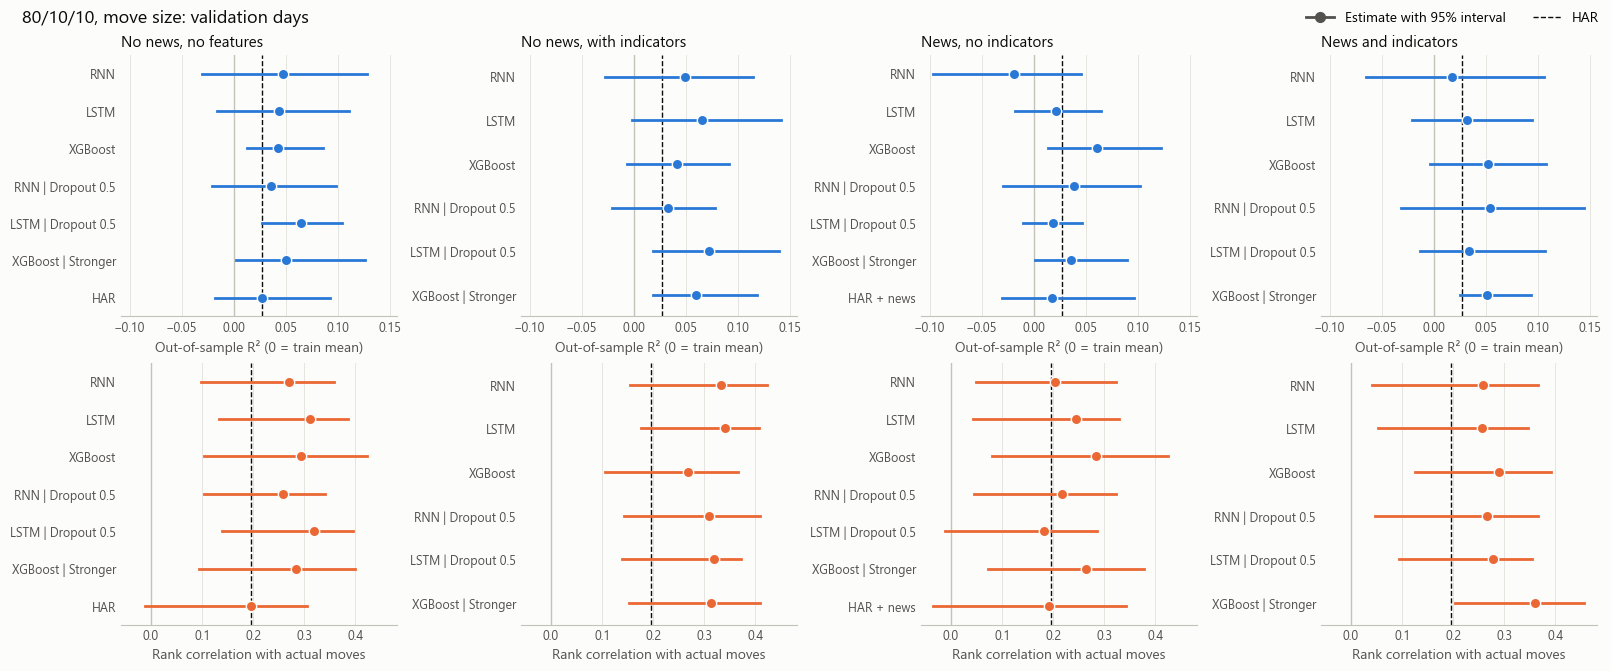

In [13]:
split_intervals = move_intervals(validation)
plot_move_intervals(split_intervals, title="80/10/10, move size: validation days")

### 80/10/10: table

The intervals are wide because there are only 123 days. MSE and MAE are shown multiplied by 10,000.

In [14]:
scale(split_intervals).drop(columns=["horizon", "days"]).sort_values("oos_r2", ascending=False)

,track,model,mse,baseline_mse,mae,baseline_mae,spread_ratio,oos_r2,oos_r2_lower,oos_r2_upper,mae_skill,mae_skill_lower,mae_skill_upper,correlation,correlation_lower,correlation_upper,rank_correlation,rank_correlation_lower,rank_correlation_upper
11,no_news_with_feature_engineering,LSTM | Dropout 0.5,7.3684,7.9379,179.5372,183.4531,0.2661,0.0717,0.0186,0.1390,0.0213,-0.0366,0.0964,0.2764,0.0974,0.3900,0.3194,0.1387,0.3714
8,no_news_with_feature_engineering,LSTM,7.4186,7.9379,181.0915,183.4531,0.2998,0.0654,-0.0015,0.1408,0.0129,-0.0564,0.1075,0.2713,0.0944,0.3868,0.3400,0.1755,0.4075
4,no_news_no_feature_engineering,LSTM | Dropout 0.5,7.4226,7.9379,179.7244,183.4531,0.2228,0.0649,0.0273,0.1042,0.0203,-0.0244,0.0746,0.2631,0.1070,0.3493,0.3194,0.1396,0.3947
15,news_with_feature_engineering,XGBoost,7.4531,7.9379,176.1875,183.4531,0.1377,0.0611,0.0138,0.1216,0.0396,0.0096,0.0705,0.2978,0.1069,0.4680,0.2843,0.0806,0.4244
12,no_news_with_feature_engineering,XGBoost | Stronger,7.4624,7.9379,176.1739,183.4531,0.1722,0.0599,0.0181,0.1178,0.0397,-0.0025,0.0907,0.2562,0.0820,0.3805,0.3128,0.1525,0.4082
23,news_with_feature_engineering_and_tech,RNN | Dropout 0.5,7.5115,7.9379,177.0629,183.4531,0.2645,0.0537,-0.0311,0.1443,0.0348,-0.0020,0.0835,0.2608,0.0696,0.4238,0.2662,0.0479,0.3665
22,news_with_feature_engineering_and_tech,XGBoost,7.5252,7.9379,180.0613,183.4531,0.1533,0.0520,-0.0041,0.1078,0.0185,-0.0153,0.0565,0.2725,0.0652,0.4317,0.2895,0.1259,0.3911
25,news_with_feature_engineering_and_tech,XGBoost | Stronger,7.5344,7.9379,177.3804,183.4531,0.0912,0.0508,0.0250,0.0929,0.0331,0.0100,0.0620,0.3193,0.1647,0.4495,0.3596,0.2045,0.4565
5,no_news_no_feature_engineering,XGBoost | Stronger,7.5403,7.9379,175.6479,183.4531,0.1958,0.0501,0.0023,0.1255,0.0425,-0.0080,0.1085,0.2218,0.0501,0.3616,0.2843,0.0935,0.4001
7,no_news_with_feature_engineering,RNN,7.5472,7.9379,184.7897,183.4531,0.2983,0.0492,-0.0273,0.1147,-0.0073,-0.0626,0.0545,0.2814,0.1255,0.4055,0.3331,0.1537,0.4228


### 80/10/10: news against no news

Positive differences favor news. MSE and MAE are shown multiplied by 10,000.

In [15]:
scale(compare_news(validation)).drop(columns="days")

,comparison,model,mse_first,mse_second,mae_first,mae_second,rank_first,rank_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,mae_improvement,mae_improvement_lower,mae_improvement_upper,rank_gain,rank_gain_lower,rank_gain_upper
0,"News vs no news, no features",RNN,8.0882,7.5619,187.9394,182.7302,0.2034,0.2691,-0.5263,-0.8850,-0.1821,-5.2092,-13.0599,2.2701,-0.0657,-0.1637,0.1073
1,"News vs no news, no features",LSTM,7.7680,7.5974,181.4610,183.2034,0.2445,0.3118,-0.1706,-0.4611,0.1069,1.7424,-5.8909,9.6959,-0.0673,-0.1337,-0.0132
2,"News vs no news, no features",XGBoost,7.4531,7.6026,176.1875,178.5844,0.2843,0.2945,0.1495,-0.0418,0.3542,2.3969,-0.5352,5.0592,-0.0103,-0.0654,0.0489
3,"News vs no news, no features",RNN | Dropout 0.5,7.6353,7.6562,182.8265,181.7050,0.2182,0.2588,0.0208,-0.2977,0.3417,-1.1215,-7.1986,5.2544,-0.0406,-0.1451,0.0530
4,"News vs no news, no features",LSTM | Dropout 0.5,7.7950,7.4226,182.6088,179.7244,0.1820,0.3194,-0.3724,-0.6365,-0.1350,-2.8844,-8.3588,2.7788,-0.1374,-0.2233,-0.0582
5,"News vs no news, no features",XGBoost | Stronger,7.6524,7.5403,177.8935,175.6479,0.2642,0.2843,-0.1120,-0.2506,0.0232,-2.2456,-5.8215,1.2483,-0.0201,-0.0582,0.0202
6,News + indicators vs indicators,RNN,7.8010,7.5472,181.8287,184.7897,0.2577,0.3331,-0.2538,-0.6282,0.0704,2.9610,-4.3292,11.0364,-0.0754,-0.1674,0.0016
7,News + indicators vs indicators,LSTM,7.6863,7.4186,180.9846,181.0915,0.2558,0.3400,-0.2678,-0.5492,0.0132,0.1070,-7.0966,8.0727,-0.0841,-0.1483,-0.0435
8,News + indicators vs indicators,XGBoost,7.5252,7.6085,180.0613,181.0715,0.2895,0.2687,0.0833,-0.0482,0.2314,1.0102,-1.9915,4.2981,0.0208,-0.0733,0.1287
9,News + indicators vs indicators,RNN | Dropout 0.5,7.5115,7.6806,177.0629,181.8562,0.2662,0.3100,0.1691,-0.2337,0.6651,4.7933,-0.0825,9.8280,-0.0438,-0.1608,0.0471


## Conclusions

**Under the rules fixed in advance, this test stops at question 1, and news shows no benefit.** There is a real but small pattern in which days are bigger, but not enough to clearly beat the train mean on MSE.

1. **Is there a pattern?** Not by the agreed rule. HAR's R² is 0.012, with an interval of -0.020 to 0.051. Its rank correlation is 0.133 (0.048 to 0.189), so it does rank days better than chance. This is still different from the return target, where no setup had an R² above zero: here 13 of the 26 fitted setups, including HAR, do, though none has an interval above zero.
2. **Does a trained model beat HAR?** No. None of the 25 comparisons has an MSE interval above zero, and 6 are clearly worse, all of them RNNs or HAR + news. The 20-day average ranks days about as well as HAR, at 0.144, so the pattern is mostly the slow level of volatility.
3. **Does news help?** No. In the 13 comparisons, news is never better on MSE or rank correlation, and is worse on MSE in 5, including HAR + news against HAR. It's better on MAE in 2 and worse in 2, which doesn't meet the rule.

**Big moves aren't predicted.** HAR predicted 0.022 for the largest move, which was 0.218. The models flag at most about 3% of days as big, against 18% that actually are, and none catches more than about 6% of them. Only the simple baselines catch more, up to about 20%, and Yesterday's precision is close to chance.

**Checked after seeing the results, so this doesn't change the rule:** the biggest 1% of days make up 33% of the train mean's squared error, which suggested that spikes were hiding a stronger pattern. Removing them only raises HAR's R² to 0.024, and removing the biggest 5% gives -0.001. So the spikes aren't hiding much.

**80/10/10:** R² is higher, up to 0.072 with an interval above zero, and rank correlation reaches 0.36. These are only 123 days, and walk-forward is the stronger evidence. News is again never better: it's worse on MSE in 3 of 13 comparisons and on rank correlation in 3.

**Limit of this test:** it only covers these news features. They're a rolling summary that ends two days before the scored move's close, and they don't include scheduled events such as earnings dates.